**Project Topic:**

**Machine Learning–Based Semantic Search and Recommendation for Product Data**

This notebook presents the development of an intelligent product search and recommendation system based on text data. The workflow includes text preprocessing and feature extraction using TF-IDF, dimensionality reduction with SVD and PCA, and the application of unsupervised machine learning models such as KMeans and KNN. Different representations and models are evaluated using appropriate metrics, and the final system provides semantic search and product recommendations based on user text queries.

There all necessary libraries for data processing and natural language processing are imported. Then, the required NLTK resources, including tokenizers and stop words, are downloaded to support text preprocessing. Finally, the prepared dataset containing product information is loaded from a CSV file into a pandas DataFrame for further analysis.

In [46]:
import pandas as pd
import nltk
import re
from nltk.stem.snowball import SnowballStemmer
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer

In [47]:
nltk.download("punkt")
nltk.download("stopwords")

In [48]:
data = pd.read_csv("processed_products_data.csv")

In [49]:
data

,Название,Цена,Рассрочка,Наличие,Модель,Страна,Производитель,Описание,Изображение,Аптеки,Категории
0,Декарис 50 мг № 2 табл.,1150,288 x 4 мес.,Есть в наличии,5997001380338,Венгрия,Гедеон Рихтер,Инструкция по медицинскому применениюлекарстве...,https://st.europharma.kz/cache/product/7876/x2...,"['Аптека №57 (г.Алматы,Жетысуский район, ул. Д...","['Лекарственные средства', 'От паразитов']"
1,911 бадяга 100 мл. гель,876,219 x 4 мес.,Есть в наличии,4607010243104,Россия,Твинс-Тек,Средство создано на основе бадяги - уникальног...,https://st.europharma.kz/cache/product/4387/x2...,"['Аптека № 58, Алматы, (Акбулак) (мкр Акбулак,...","['Витамины и БАДы', 'БАДы', 'Для кожи']"
2,"Аскорбинка Витаминка ""София"" с ароматом лимона...",85,21 x 4 мес.,Есть в наличии,4870004384620,Казахстан,Ева-1 ТОО,Биологически активная добавка к пище. Не являе...,https://st.europharma.kz/cache/product/8554/40...,"['Аптека №57 (г.Алматы,Жетысуский район, ул. Д...","['Витамины и БАДы', 'Витамины и минералы', 'Дл..."
3,"La Roche Цикапласт губы барьерный бальзам 7,5 гр",5540,1 385 x 4 мес.,Есть в наличии,30106659,Россия,LA ROCHE-POSAY,Восстанавливающий бальзам-барьер La Roche-Posa...,https://st.europharma.kz/cache/product/1490/x2...,"['Аптека № 75, Алматы, Абая Жарокова) (ул.Абая...","['Красота и гигиена', 'Дермакосметика']"
4,Фрутоняня пюре морковь 4месяцев 80 г,715,179 x 4 мес.,Есть в наличии,4600338004952,Россия,АО ПРОГРЕСС (Россия),Бренд Фрутоняня Возраст 4 мес+ Вид пюре Фрукто...,https://st.europharma.kz/cache/product/26714/x...,"['Аптека №294 (Алматы ,Кульджинский тракт, 14,...","['Мать и дитя', 'Детское питание и кормление',..."
...,...,...,...,...,...,...,...,...,...,...,...
3412,Грелка комбинированная тип Б-1 в инд уп,2225,556 x 4 мес.,Есть в наличии,4823060801372,Украина,Киев Гума,Назначение.Грелка типа Б предназначена для мес...,https://st.europharma.kz/cache/product/5480/40...,"['Аптека № 91, Алматы, (Магнум Думан) (г.Алмат...","['Изделия мед. назначения', 'Медицинские издел..."
3413,Biolane бальзам защитный для сосков с ланолино...,5260,1 315 x 4 мес.,Есть в наличии,3286010027566,Франция,Biolane,Гипоаллергенный бальзам для кормящих женщих Bi...,https://st.europharma.kz/cache/product/25151/x...,"['Аптека № 83, Алматы, (Сейфулина Калинина) (г...","['Мать и дитя', 'Товары для мам', 'Косметика и..."
3414,Доппельгерц Актив Фолиевая к-та + Вит. В6+В12+...,4320,1 080 x 4 мес.,Есть в наличии,4009932554748,Германия,"Queisser Pharma GmbH&Co,",Лекарственная формаБАДДоппельгерц® Актив Фолие...,https://st.europharma.kz/cache/product/607/400...,"['Аптека №260, Алматы, (Алтынсарин) (11-й микр...","['Витамины и БАДы', 'БАДы', 'Для сердца']"
3415,Тонометр A&D полуавтоматический (UA-604),14607,3 652 x 4 мес.,Есть в наличии,4981046050074,Япония,A&D Company,"Компактный, легкий, недорогой полуавтоматическ...",https://st.europharma.kz/cache/product/6213/40...,"['Аптека №40 (г. Алматы, Проспект Серкебаева 1...","['Изделия мед. назначения', 'Медицинские прибо..."


Next, text fields are combined, cleaned, and stemmed, after which TF-IDF is applied to convert the text into numerical features for machine learning.

In [50]:
data["Категории_строка"] = data["Категории"].apply(
    lambda x: " ".join(eval(x)) if isinstance(x, str) and x.startswith("[") else ""
)

In [51]:
data["text"] = (
    data["Название"].fillna("") + " " +
    data["Описание"].fillna("") + " " +
    data["Категории_строка"].fillna("")
)

In [52]:
stemmer = SnowballStemmer("russian")

def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    words = re.findall(r"[а-яa-z]+", text)
    words = [stemmer.stem(w) for w in words]
    return " ".join(words)

data["text_processed"] = data["text"].apply(preprocess_text)

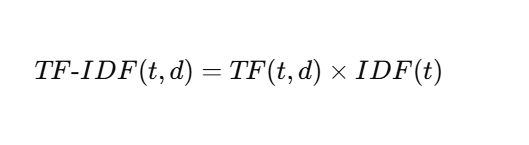

In [53]:
russian_stopwords = stopwords.words("russian")

tfidf = TfidfVectorizer(
    stop_words=russian_stopwords,
    max_features=5000
)

X_tfidf = tfidf.fit_transform(data["text_processed"])

print("TF-IDF shape:", X_tfidf.shape)

TF-IDF shape: (3417, 5000)


**Choosing the Number of Clusters (Elbow Method)**

The Elbow Method is used to determine the optimal number of clusters for KMeans by analyzing how inertia changes with different values of k.

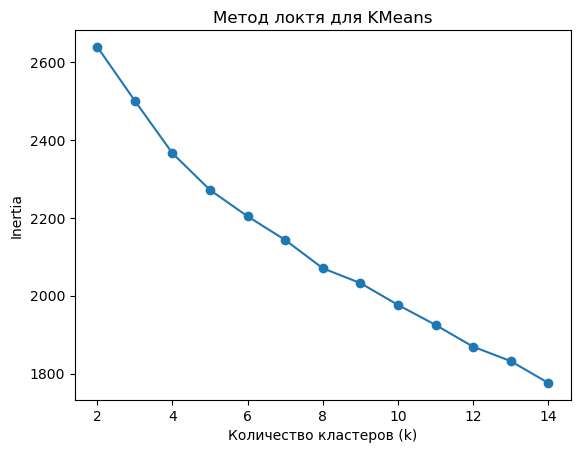

In [54]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
k_range = range(2, 15)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_tfidf)
    inertia.append(kmeans.inertia_)

plt.figure()
plt.plot(k_range, inertia, marker="o")
plt.xlabel("Количество кластеров (k)")
plt.ylabel("Inertia")
plt.title("Метод локтя для KMeans")
plt.show()

**KMeans Clustering on TF-IDF Features**

KMeans clustering is applied directly to TF-IDF features using the selected number of clusters. Each product is assigned to a cluster, and the distribution of products across clusters is analyzed.

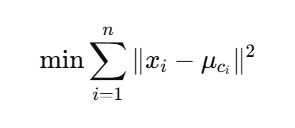

In [55]:
k_optimal = 8

kmeans = KMeans(
    n_clusters=k_optimal,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_tfidf)

data["cluster_kmeans"] = clusters

print(data["cluster_kmeans"].value_counts())

cluster_kmeans
2    940
7    745
1    673
3    439
6    220
4    173
5    123
0    104
Name: count, dtype: int64


**Evaluating Clustering Quality (TF-IDF)**

The Silhouette Score is calculated to measure the quality of clustering based on TF-IDF features.

In [56]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_tfidf, clusters)
print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.045


**Dimensionality Reduction with SVD**

At this step, Truncated SVD is applied to reduce the dimensionality of the TF-IDF matrix. This helps remove noise and makes clustering and recommendation models more efficient.

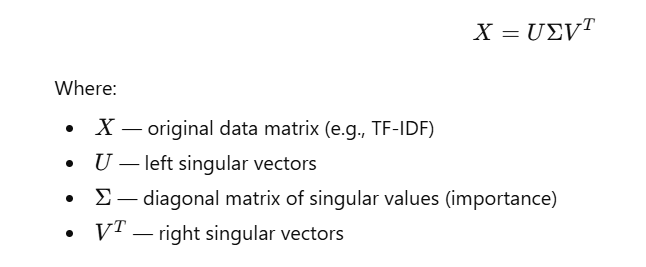

In [57]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=100, random_state=42)
X_svd = svd.fit_transform(X_tfidf)

**KMeans Clustering on SVD Features**

KMeans is applied again, this time using SVD-reduced features. This approach aims to improve clustering quality by reducing noise and dimensionality.

In [58]:
k_optimal = 8

kmeans = KMeans(
    n_clusters=k_optimal,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_svd)

data["cluster_kmeans"] = clusters

print(data["cluster_kmeans"].value_counts())

cluster_kmeans
6    1040
0     945
1     643
2     345
4     162
3     117
5      88
7      77
Name: count, dtype: int64


In [59]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_svd, clusters)
print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.11


**PCA + KMeans**

PCA is applied to reduce dimensionality, after which KMeans clustering is performed and evaluated using the Silhouette Score.

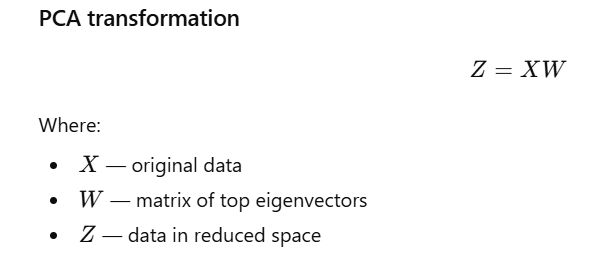

PCA projects data onto directions with maximum variance.

In [60]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50, random_state=42)
X_pca = pca.fit_transform(X_tfidf.toarray())

print("Explained variance:", round(pca.explained_variance_ratio_.sum(), 3))

k = 6
kmeans_pca = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters_pca = kmeans_pca.fit_predict(X_pca)

score_pca = silhouette_score(X_pca, clusters_pca)
print("PCA + KMeans Silhouette:", round(score_pca, 3))

data["cluster_pca_kmeans"] = clusters_pca

Explained variance: 0.311
PCA + KMeans Silhouette: 0.132


**KNN on TF-IDF**

KNN is trained on TF-IDF features to recommend similar products based on cosine similarity.

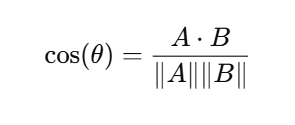

In [61]:
from sklearn.neighbors import NearestNeighbors

knn = NearestNeighbors(
    n_neighbors=6,
    metric="cosine"
)
knn.fit(X_tfidf)

def recommend_knn(product_index, top_n=5):
    distances, indices = knn.kneighbors(
        X_tfidf[product_index],
        n_neighbors=top_n + 1
    )

    recs = data.iloc[indices[0][1:]][
        ["Название", "Цена", "Аптеки"]
    ].copy()

    recs["Similarity"] = 1 - distances[0][1:]
    return recs

recommend_knn(0)

,Название,Цена,Аптеки,Similarity
193,Декарис 150мг № 1 табл.,1035,"['Аптека № 74, Алматы, (Самал 1) (г.Алматы, Ме...",0.631005
3251,Пирантел 250 мг № 3 табл.,985,"['Аптека №222 (ул. Розыбакиева 33/1 ТК ""Оптовк...",0.430764
86,Гельминтокс 250 мг № 3 табл.,1400,"['Аптека №311 (улица Курмангазы, дом 144, НП 7...",0.386915
112,"Кетотифен 1 мг, №30, табл.",415,"['Аптека № 91, Алматы, (Магнум Думан) (г.Алмат...",0.384333
2904,Кетотифен 1 мг № 30 табл,467,"['Аптека №263, Алматы, (Жандосова) (Жандосова ...",0.384333


In [62]:
distances, _ = knn.kneighbors(X_tfidf, n_neighbors=6)

mean_similarity = np.mean(1 - distances[:, 1:])
print("KNN mean similarity:", round(mean_similarity, 3))

KNN mean similarity: 0.601


**KNN + SVD**

SVD is applied to TF-IDF features, and KNN is used on the reduced space to improve recommendation quality.

In [63]:
knn_svd = NearestNeighbors(n_neighbors=6, metric="cosine")
knn_svd.fit(X_svd)

def recommend_knn_svd(product_index, top_n=5):
    distances, indices = knn_svd.kneighbors(
        X_svd[product_index].reshape(1, -1),
        n_neighbors=top_n + 1
    )

    recs = data.iloc[indices[0][1:]][
        ["Название", "Цена", "Аптеки"]
    ].copy()

    recs["Similarity"] = 1 - distances[0][1:]
    return recs


distances_svd, _ = knn_svd.kneighbors(X_svd, n_neighbors=6)
mean_similarity_svd = np.mean(1 - distances_svd[:, 1:])
print("KNN + SVD mean similarity:", round(mean_similarity_svd, 3))

KNN + SVD mean similarity: 0.911


**KNN + PCA**

KNN is also tested on PCA-reduced features to compare similarity-based recommendation performance.

In [64]:
knn_pca = NearestNeighbors(n_neighbors=6, metric="cosine")
knn_pca.fit(X_pca)

def recommend_knn_pca(product_index, top_n=5):
    distances, indices = knn_pca.kneighbors(
        X_pca[product_index].reshape(1, -1),
        n_neighbors=top_n + 1
    )

    recs = data.iloc[indices[0][1:]][
        ["Название", "Цена", "Аптеки"]
    ].copy()

    recs["Similarity"] = 1 - distances[0][1:]
    return recs


distances_pca, _ = knn_pca.kneighbors(X_pca, n_neighbors=6)
mean_similarity_pca = np.mean(1 - distances_pca[:, 1:])
print("KNN + PCA mean similarity:", round(mean_similarity_pca, 3))

KNN + PCA mean similarity: 0.928


Final Recommendation System

The final system uses TF-IDF + SVD + KNN to return the most relevant products for a user text query.

In [65]:
def recommend_by_query_svd(query, top_n=5):
    
    query_processed = preprocess_text(query)
    query_tfidf = tfidf.transform([query_processed])

    
    query_svd = svd.transform(query_tfidf)


    distances, indices = knn_svd.kneighbors(
        query_svd,
        n_neighbors=top_n
    )

    
    results = data.iloc[indices[0]][
        ["Название", "Цена", "Аптеки"]
    ].copy()

    results["Similarity"] = 1 - distances[0]
    return results



recommend_by_query_svd("от горла", top_n=5)

,Название,Цена,Аптеки,Similarity
2724,"Средство для полоскания рта с ром.,кален.,шалф.",815,"['Аптека №260, Алматы, (Алтынсарин) (11-й микр...",0.763749
2612,Средство для полоскания рта с эвкалиптом,792,"['Аптека № 83, Алматы, (Сейфулина Калинина) (г...",0.752955
2952,Средство для полоскания рта с прополюсом,880,"['Аптека №57 (г.Алматы,Жетысуский район, ул. Д...",0.741351
545,Средство для полоскания рта с корой дуба,950,"['Аптека № 81, Алматы, (Магнум Абая) (Микрорай...",0.732388
3143,Средство для полоскания рта с морской солью,830,"['Аптека № 59, Алматы, (Радостовцова 292) (Бос...",0.728099


**Final Conclusion**

Several machine learning approaches with different text representations were compared in this work. Clustering quality was evaluated using the Silhouette Score. The TF-IDF + KMeans model showed low Silhouette values due to the sparse nature of TF-IDF features. Applying dimensionality reduction improved clustering quality, and the PCA + KMeans model achieved higher Silhouette scores, indicating better data structure after dimensionality reduction.

The recommendation system was evaluated using mean cosine similarity. KNN based on TF-IDF produced good results, while dimensionality reduction further improved recommendation quality. A comparison between KNN + PCA and KNN + SVD showed that PCA yields very high similarity but may reduce recommendation diversity. The KNN + SVD model achieved high mean similarity while maintaining a better balance between similarity and diversity.

Based on the evaluation metrics, the TF-IDF + SVD + KNN combination was selected as the final model, as it provides robust and balanced recommendation quality and is well suited for practical product search applications.